In [1]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from matplotlib import pyplot as plt
from sklearn.metrics import accuracy_score

In [2]:
data = pd.read_csv('chapter4_task_data.csv')
data.head()

,x1,x2,y
0,82.743436,68.322815,NaN
1,14.437968,54.716677,NaN
2,88.950582,15.264268,NaN
3,78.280878,26.313806,NaN
4,78.210116,58.694901,NaN


In [3]:
x = data.drop(['y'],axis=1)
km = KMeans(n_clusters=2,random_state=0)
km.fit(x)

/Users/mima0000/anaconda3/envs/ai_tec/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


KMeans(n_clusters=2, random_state=3)

In [4]:
centers = km.cluster_centers_
y_predict = km.predict(x)
y_predict

array([0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0,
       0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1,
       0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      dtype=int32)

In [5]:
data_origin = pd.read_csv('chapter4_task_data_real.csv')
data_origin.head()

,x1,x2,y
0,82.743436,68.322815,0
1,14.437968,54.716677,1
2,88.950582,15.264268,0
3,78.280878,26.313806,0
4,78.210116,58.694901,0


In [6]:
y_origin = data_origin.loc[:,'y']
pd.value_counts(y_origin)

y
0    167
1    118
Name: count, dtype: int64

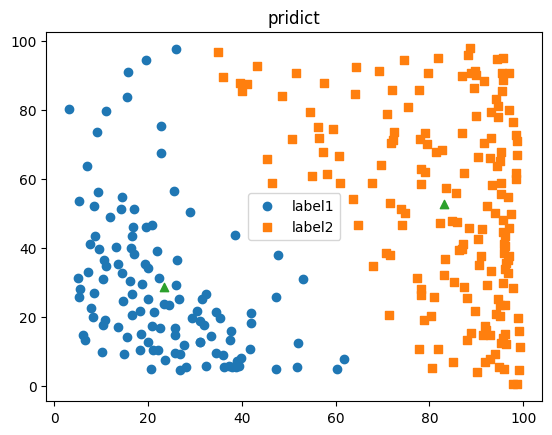

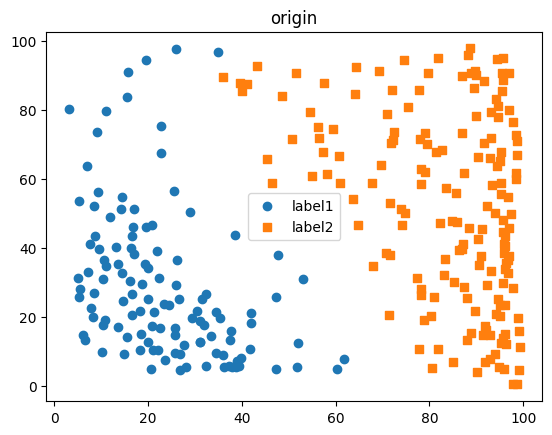

In [7]:
fig1 = plt.figure()
plt.title('pridict')
label1_pre = plt.scatter(data.loc[:,'x1'][y_predict==1],data.loc[:,'x2'][y_predict==1])
label2_pre = plt.scatter(data.loc[:,'x1'][y_predict==0],data.loc[:,'x2'][y_predict==0],marker='s')
plt.scatter(centers[:,0],centers[:,1],marker='^')
plt.legend((label1_pre,label2_pre),('label1','label2'))

fig2 = plt.figure()
plt.title('origin')
label1_ori = plt.scatter(data.loc[:,'x1'][y_origin==1],data.loc[:,'x2'][y_origin==1])
label2_ori = plt.scatter(data.loc[:,'x1'][y_origin==0],data.loc[:,'x2'][y_origin==0],marker='s')
plt.legend((label1_ori,label2_ori),('label1','label2'))

plt.show()

In [8]:
accuracy_score(y_origin,y_predict)

0.9964912280701754

In [9]:
data_origin.head()

,x1,x2,y
0,82.743436,68.322815,0
1,14.437968,54.716677,1
2,88.950582,15.264268,0
3,78.280878,26.313806,0
4,78.210116,58.694901,0


In [10]:
from sklearn.neighbors import KNeighborsClassifier
y = data_origin.loc[:,'y']
knn = KNeighborsClassifier(n_neighbors=2)
knn.fit(x,y)

KNeighborsClassifier(n_neighbors=2)

In [11]:
y_predict_knn = knn.predict(x)
accuracy_score(y_origin,y_predict_knn)

0.9964912280701754